# 05 · Experimento adicional y análisis de errores
**Entrega 2 · días 11–13.** Necesita GPU y E0–E3 ejecutados. La hipótesis del experimento adicional debe estar escrita antes.

In [1]:
# PREPARACIÓN (igual en todos los notebooks): conecta Drive, entra a la carpeta del proyecto y deja listos los datos.
from google.colab import drive
drive.mount('/content/drive')

PROYECTO = '/content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion'   # carpeta del proyecto dentro de su Google Drive

import os, sys
os.chdir(PROYECTO)
sys.path.insert(0, PROYECTO)

from src.datos import descargar_dataset
# El .zip se guarda una sola vez en Drive; las fotos se descomprimen en el disco de Colab (más rápido).
RAIZ = str(descargar_dataset(destino='/content/datos', carpeta_zip=PROYECTO + '/data'))
os.environ['YUCA_DATOS'] = RAIZ
print('Proyecto:', os.getcwd())
print('Datos   :', RAIZ)

Mounted at /content/drive
[1/2] Ya existe el archivo /content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion/data/cassavaleafdata.zip; no se descarga de nuevo.
[2/2] Descomprimiendo...
[ok] Dataset listo en: /content/datos/cassavaleafdata
Proyecto: /content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion
Datos   : /content/datos/cassavaleafdata


In [2]:
import torch
print('GPU disponible:', torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'SIN GPU: menú Entorno de ejecución > Cambiar tipo de entorno > T4 GPU')

GPU disponible: True
Tesla T4


## Experimento adicional · opción A: robustez al brillo
No se entrena nada. Se evalúan E1 y E3 sobre **copias** del mismo conjunto de prueba con el brillo multiplicado por cada factor.
Lo demás no cambia. Factor 1.0 debe reproducir exactamente el resultado original (comprobación).

[2026-11-18 05:36:39] E1 brillo x0.5: accuracy 0.6960 macro-F1 0.6041
[2026-11-18 05:36:56] E1 brillo x0.75: accuracy 0.7353 macro-F1 0.6496
[2026-11-18 05:37:10] E1 brillo x1.0: accuracy 0.7411 macro-F1 0.6590
[2026-11-18 05:37:31] E1 brillo x1.25: accuracy 0.7369 macro-F1 0.6473
[2026-11-18 05:37:52] E1 brillo x1.5: accuracy 0.7088 macro-F1 0.6184
[2026-11-18 05:38:12] E3 brillo x0.5: accuracy 0.7034 macro-F1 0.6281
[2026-11-18 05:38:31] E3 brillo x0.75: accuracy 0.7432 macro-F1 0.6752
[2026-11-18 05:38:44] E3 brillo x1.0: accuracy 0.7576 macro-F1 0.6870
[2026-11-18 05:39:05] E3 brillo x1.25: accuracy 0.7485 macro-F1 0.6745
[2026-11-18 05:39:25] E3 brillo x1.5: accuracy 0.6918 macro-F1 0.6163


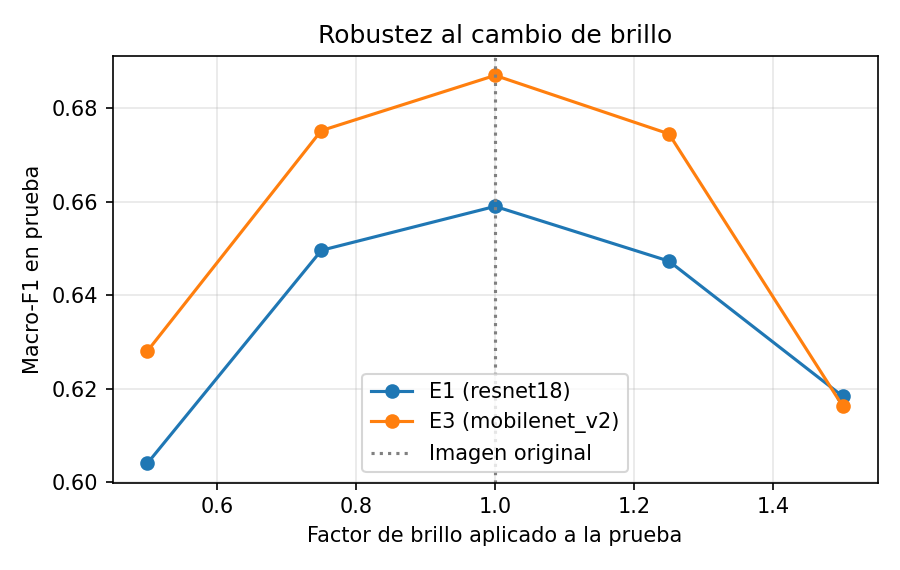

,experimento,modelo,brillo,accuracy,macro_f1,recall_cbb,recall_cbsd,recall_cgm,recall_cmd,recall_healthy
0,E1,resnet18,0.50,0.6960,0.6041,0.4387,0.7006,0.4845,0.7810,0.8571
1,E1,resnet18,0.75,0.7353,0.6496,0.5097,0.6216,0.6395,0.8589,0.7810
2,E1,resnet18,1.00,0.7411,0.6590,0.4839,0.6383,0.6783,0.8646,0.7048
3,E1,resnet18,1.25,0.7369,0.6473,0.5097,0.6590,0.6008,0.8758,0.5905
4,E1,resnet18,1.50,0.7088,0.6184,0.5355,0.7048,0.4884,0.8318,0.4857
5,E3,mobilenet_v2,0.50,0.7034,0.6281,0.6323,0.5842,0.6008,0.7912,0.8667
6,E3,mobilenet_v2,0.75,0.7432,0.6752,0.6258,0.6258,0.6938,0.8330,0.8190
7,E3,mobilenet_v2,1.00,0.7576,0.6870,0.6323,0.6486,0.7132,0.8578,0.7048
8,E3,mobilenet_v2,1.25,0.7485,0.6745,0.6129,0.7048,0.7016,0.8307,0.5714
9,E3,mobilenet_v2,1.50,0.6918,0.6163,0.5871,0.7006,0.6667,0.7449,0.4190


In [3]:
from src import adicional, analisis
from IPython.display import Image as Mostrar, display
import pandas as pd
tabla = adicional.ejecutar(('E1', 'E3'))
display(Mostrar('resultados/adicional_brillo/robustez_brillo.png'))
tabla

## Experimento adicional · opción B: augmentation moderado (solo si el equipo elige esta)
Repite E1 con las mismas condiciones, pero las fotos de **entrenamiento** reciben recortes, giros y volteos leves.
Validación y prueba no se tocan. El profesor exige una de las dos opciones; hacer ambas es decisión del equipo.

In [4]:
EJECUTAR_AUGMENTATION = False   # <- decisión del equipo
if EJECUTAR_AUGMENTATION:
    from src.entrenar import ejecutar
    ejecutar('E1_aug')
    display(analisis.tabla_consolidada(('E1', 'E1_aug')).T)
    display(analisis.tabla_por_clase(('E1', 'E1_aug'), 'f1'))

## Confusiones más frecuentes de cada modelo

In [5]:
for exp in ('E1', 'E2', 'E3'):
    print(exp)
    display(analisis.pares_confundidos(exp))

E1


,real,predicha,veces,% de la clase real
0,cbsd,cbb,92,19.1
1,cmd,cgm,56,6.3
2,cgm,cmd,44,17.1
3,cbsd,cmd,41,8.5
4,cmd,cbsd,40,4.5
5,cbb,cbsd,38,24.5


E2


,real,predicha,veces,% de la clase real
0,cmd,cgm,50,5.6
1,cgm,cmd,39,15.1
2,cbsd,cmd,36,7.5
3,cbb,cbsd,34,21.9
4,cbsd,cbb,33,6.9
5,cbsd,cgm,29,6.0


E3


,real,predicha,veces,% de la clase real
0,cbsd,cbb,106,22.0
1,cmd,cgm,51,5.8
2,cmd,cbsd,44,5.0
3,cgm,cmd,39,15.1
4,cbsd,cgm,27,5.6
5,cbsd,cmd,26,5.4


## Inspección de errores reales (mínimo 8)
Se muestran los errores con mayor confianza de cada modelo (criterio fijo, para no escoger a conveniencia).
Para cada uno, el equipo escribe su hipótesis en `docs/04_analisis_errores.md`: ¿confusión entre síntomas parecidos?, ¿fondo?, ¿iluminación?, ¿foto borrosa?, ¿lesión pequeña?, ¿etiqueta dudosa?

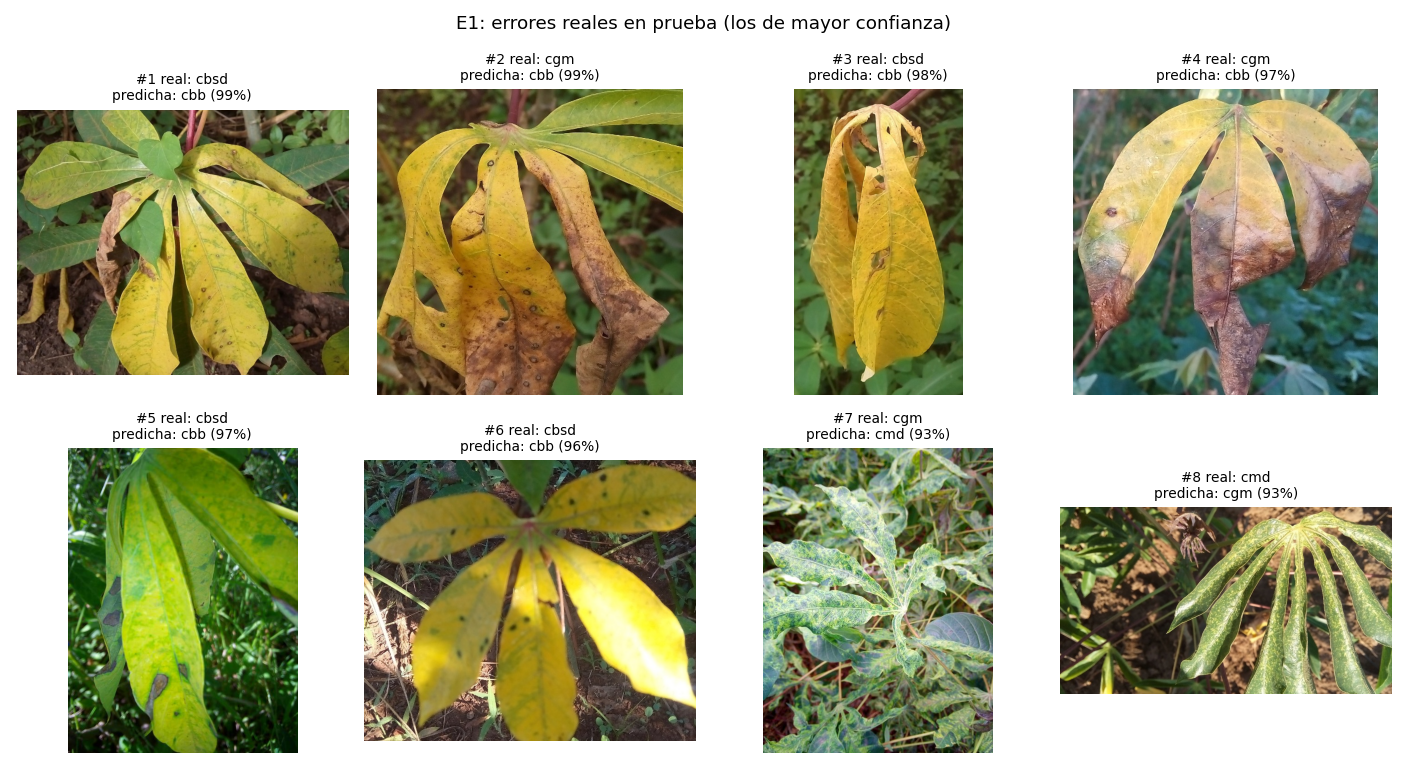

,ruta,real,predicha,confianza
0,test/cbsd/test-cbsd-311.jpg,cbsd,cbb,0.9902
1,test/cgm/test-cgm-136.jpg,cgm,cbb,0.9882
2,test/cbsd/test-cbsd-88.jpg,cbsd,cbb,0.9839
3,test/cgm/test-cgm-102.jpg,cgm,cbb,0.9729
4,test/cbsd/test-cbsd-215.jpg,cbsd,cbb,0.9708
5,test/cbsd/test-cbsd-331.jpg,cbsd,cbb,0.9580
6,test/cgm/test-cgm-87.jpg,cgm,cmd,0.9313
7,test/cmd/test-cmd-294.jpg,cmd,cgm,0.9284


In [6]:
EXPERIMENTO = 'E1'
errores = analisis.galeria_errores(EXPERIMENTO, n=8)
display(Mostrar(f'resultados/{EXPERIMENTO}/galeria_errores.png'))
errores[['ruta', 'real', 'predicha', 'confianza']]

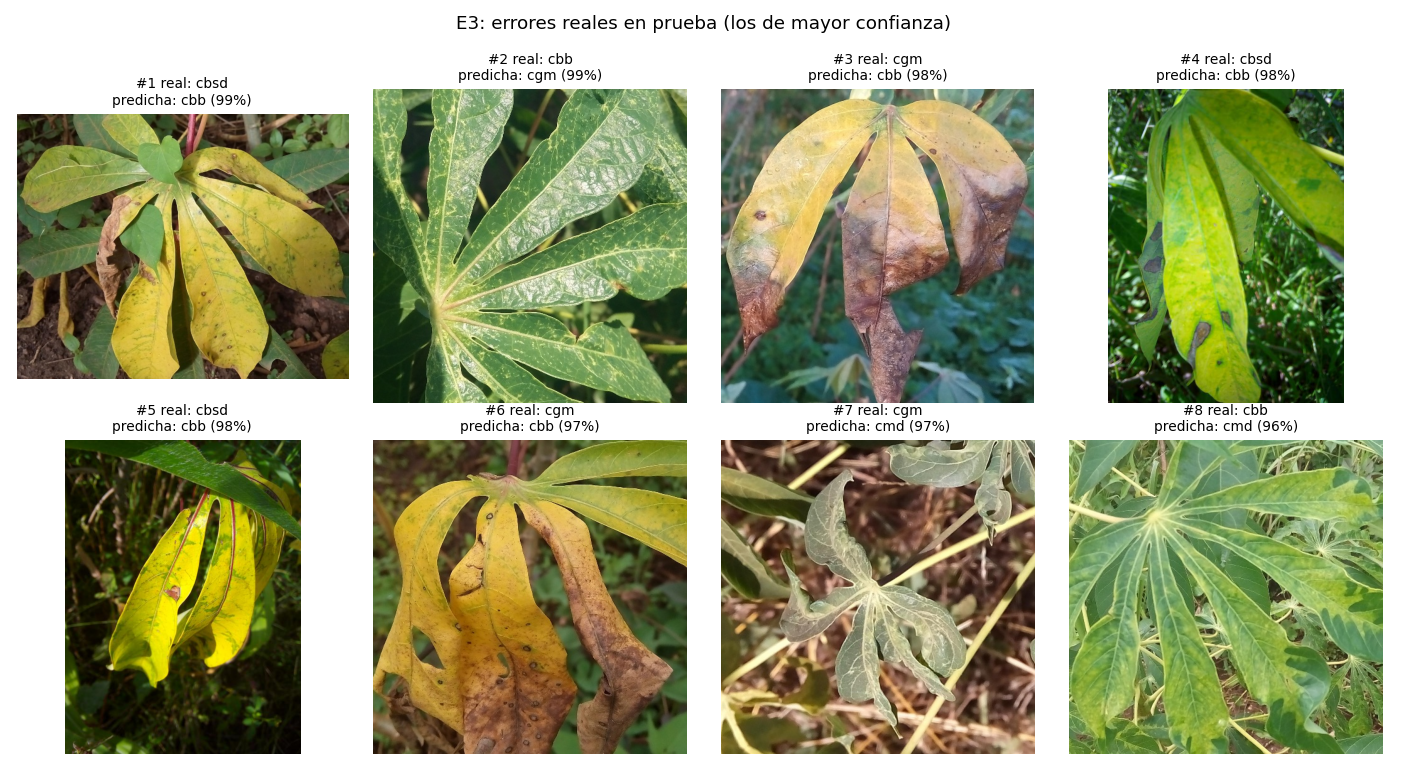

,ruta,real,predicha,confianza
0,test/cbsd/test-cbsd-311.jpg,cbsd,cbb,0.9941
1,test/cbb/test-cbb-72.jpg,cbb,cgm,0.9902
2,test/cgm/test-cgm-102.jpg,cgm,cbb,0.9848
3,test/cbsd/test-cbsd-215.jpg,cbsd,cbb,0.9820
4,test/cbsd/test-cbsd-322.jpg,cbsd,cbb,0.9785
5,test/cgm/test-cgm-136.jpg,cgm,cbb,0.9715
6,test/cgm/test-cgm-151.jpg,cgm,cmd,0.9687
7,test/cbb/test-cbb-75.jpg,cbb,cmd,0.9603


In [7]:
errores3 = analisis.galeria_errores('E3', n=8)
display(Mostrar('resultados/E3/galeria_errores.png'))
errores3[['ruta', 'real', 'predicha', 'confianza']]

In [8]:
# ¿Se equivocan E1 y E3 en las mismas fotos?
a = pd.read_csv('resultados/E1/predicciones_test.csv').set_index('ruta')['acierto']
b = pd.read_csv('resultados/E3/predicciones_test.csv').set_index('ruta')['acierto']
pd.crosstab(a.rename('E1 acierta'), b.rename('E3 acierta'))

E3 acierta,False,True
E1 acierta,,
False,289,199
True,168,1229


## Grad-CAM (opcional, recomendado para 4 imágenes)
El mapa de calor muestra qué zonas influyeron más en la respuesta. **No demuestra causalidad** ni que el modelo haya
reconocido la enfermedad: solo indica dónde hubo más activación para esa clase.

In [9]:
for exp in ('E1', 'E3'):
    display(Mostrar(str(analisis.gradcam_galeria(exp, n=4))))

Output hidden; open in https://colab.research.google.com to view.

## Tabla final

In [10]:
analisis.graficas_comparacion().T

,0,1,2,3
Exp.,E0,E1,E2,E3
Modelo,cnn_pequena,resnet18,resnet18,mobilenet_v2
Accuracy,0.5973,0.7411,0.817,0.7576
Macro-F1,0.4638,0.659,0.7457,0.687
Val macro-F1,0.4532,0.6617,0.7484,0.6975
Mejor época,8,8,5,8
Entren. (s),342.2,539.4,262.9,526.3
Entren. acumulado (s),342.2,539.4,694.8,526.3
Inferencia ms/img (lote 1),0.608,3.849,3.85,5.099
Inferencia ms/img (en lote),0.033,0.858,0.883,0.948


In [2]:
import pandas as pd, json
from src import analisis
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('== BRILLO ==')
print(pd.read_csv('resultados/adicional_brillo/resultados_brillo.csv').to_string(index=False))
print('\n== E1 frente a E1_aug ==')
print(analisis.tabla_consolidada(('E1','E1_aug'))[['Exp.','Accuracy','Macro-F1','Val macro-F1','Mejor época','Entren. (s)']].to_string(index=False))
print(analisis.tabla_por_clase(('E1','E1_aug'),'f1').to_string())
print('\n== Errores de E1 ==')
print(pd.read_csv('resultados/E1/errores_inspeccionados.csv')[['ruta','real','predicha','confianza']].to_string(index=False))

ModuleNotFoundError: No module named 'src'

In [3]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys
os.chdir('/content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion'); sys.path.insert(0, os.getcwd())

import pandas as pd
from src import analisis
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('== BRILLO ==')
print(pd.read_csv('resultados/adicional_brillo/resultados_brillo.csv').to_string(index=False))
print('\n== E1 frente a E1_aug ==')
print(analisis.tabla_consolidada(('E1','E1_aug'))[['Exp.','Accuracy','Macro-F1','Val macro-F1','Mejor época','Entren. (s)']].to_string(index=False))
print(analisis.tabla_por_clase(('E1','E1_aug'),'f1').to_string())
print('\n== Errores de E1 ==')
print(pd.read_csv('resultados/E1/errores_inspeccionados.csv')[['ruta','real','predicha','confianza']].to_string(index=False))

Mounted at /content/drive
== BRILLO ==
experimento       modelo  brillo  accuracy  macro_f1  recall_cbb  recall_cbsd  recall_cgm  recall_cmd  recall_healthy
         E1     resnet18    0.50    0.6960    0.6041      0.4387       0.7006      0.4845      0.7810          0.8571
         E1     resnet18    0.75    0.7353    0.6496      0.5097       0.6216      0.6395      0.8589          0.7810
         E1     resnet18    1.00    0.7411    0.6590      0.4839       0.6383      0.6783      0.8646          0.7048
         E1     resnet18    1.25    0.7369    0.6473      0.5097       0.6590      0.6008      0.8758          0.5905
         E1     resnet18    1.50    0.7088    0.6184      0.5355       0.7048      0.4884      0.8318          0.4857
         E3 mobilenet_v2    0.50    0.7034    0.6281      0.6323       0.5842      0.6008      0.7912          0.8667
         E3 mobilenet_v2    0.75    0.7432    0.6752      0.6258       0.6258      0.6938      0.8330          0.8190
         E3 mobil

In [4]:
from src.entrenar import ejecutar
from src import analisis
m_aug = ejecutar('E1_aug')
print(analisis.tabla_consolidada(('E1','E1_aug'))[['Exp.','Accuracy','Macro-F1','Val macro-F1','Mejor época','Entren. (s)']].to_string(index=False))
print(analisis.tabla_por_clase(('E1','E1_aug'),'f1').to_string())

[2026-11-18 06:29:06] === E1_aug: Backbone A congelado, solo cabeza + augmentation ===
[2026-11-18 06:29:06] Dispositivo: Tesla T4 | semilla: 42
[2026-11-18 06:29:10] Imágenes: train=5600 val=1877 test=1885
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 207MB/s]


[2026-11-18 06:29:11] Parámetros: 11,179,077 totales, 2,565 entrenables, 44.75 MB


FileNotFoundError: Caught FileNotFoundError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/worker.py", line 375, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/fetch.py", line 54, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion/src/dataset.py", line 69, in __getitem__
    imagen = Image.open(self.raiz / fila["ruta"]).convert("RGB")
             ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 3513, in open
    fp = builtins.open(filename, "rb")
FileNotFoundError: [Errno 2] No such file or directory: 'data/cassavaleafdata/train/cgm/train-cgm-281.jpg'


In [6]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys
PROYECTO = '/content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion'
os.chdir(PROYECTO); sys.path.insert(0, PROYECTO)

from src.datos import descargar_dataset
RAIZ = str(descargar_dataset(destino='/content/datos', carpeta_zip=PROYECTO + '/data'))
os.environ['YUCA_DATOS'] = RAIZ

from src.entrenar import ejecutar
from src import analisis
m_aug = ejecutar('E1_aug')
print(analisis.tabla_consolidada(('E1','E1_aug'))[['Exp.','Accuracy','Macro-F1','Val macro-F1','Mejor época','Entren. (s)']].to_string(index=False))
print(analisis.tabla_por_clase(('E1','E1_aug'),'f1').to_string())

from IPython.display import Image as Mostrar, display
for exp in ('E1', 'E3'):
    display(Mostrar(str(analisis.gradcam_galeria(exp, n=4))))

Output hidden; open in https://colab.research.google.com to view.